<a href="https://colab.research.google.com/github/trantuan303/HM/blob/main/c1/baiolop/bai3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kích thước dữ liệu: (442, 10)
Số mẫu: 442
Các đặc trưng: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Số mẫu huấn luyện: 353
Số mẫu kiểm tra: 89

Giá trị thực tế: [219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]
Giá trị dự đoán: [139.55 179.52 134.04 291.42 123.79  92.17 258.23 181.34  90.22 108.63]

Sai số bình phương trung bình MSE: 2900.19
Hệ số xác định R2: 0.453


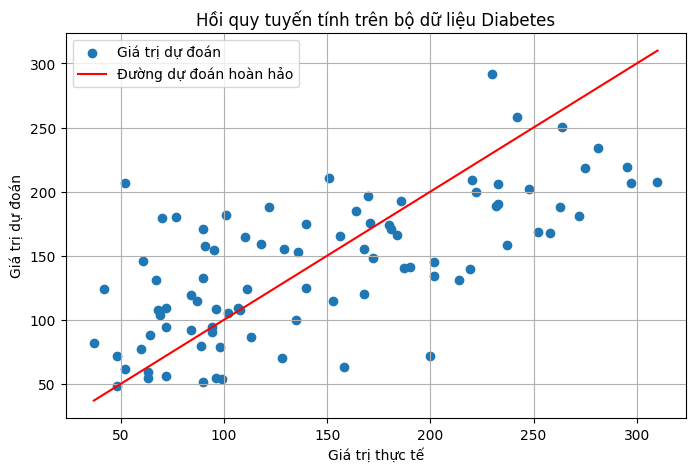

In [2]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải bộ dữ liệu
data = load_diabetes()

X = data.data
y = data.target

print("Kích thước dữ liệu:", X.shape)
print("Số mẫu:", len(y))
print("Các đặc trưng:", data.feature_names)

# 2. Chia dữ liệu thành tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Số mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))

# 3. Xây dựng và huấn luyện mô hình
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Dự đoán kết quả
y_pred = model.predict(X_test)

print("\nGiá trị thực tế:", y_test[:10])
print("Giá trị dự đoán:", np.round(y_pred[:10], 2))

# 5. Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nSai số bình phương trung bình MSE:", round(mse, 2))
print("Hệ số xác định R2:", round(r2, 3))

# 6. Trực quan hóa kết quả
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, label="Giá trị dự đoán")

# Đường tham chiếu dự đoán hoàn hảo
gia_tri = np.linspace(min(y_test), max(y_test), 100)
plt.plot(gia_tri, gia_tri, color="red",
         label="Đường dự đoán hoàn hảo")

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title("Hồi quy tuyến tính trên bộ dữ liệu Diabetes")
plt.legend()
plt.grid(True)
plt.show()
